In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import seaborn as sns

In [3]:
df = pd.read_csv(r"C:\Users\arsha\Desktop\capstone\dataset_wsn.csv")
df.sample(10)

,Date,Time,epoch,moteid,temperature,humidity,light,voltage
892488,22-03-2004,3:15:58 PM,31480,24,95.4974,43.1858,920.00,2.36622
236777,07-03-2004,3:44:10 PM,24812,7,26.1918,35.6456,264.96,2.65143
437118,08-03-2004,11:22:13 PM,28608,12,21.9484,38.1213,1.38,2.59354
654918,19-03-2004,12:42:19 PM,59008,19,122.1530,23.3435,235.52,2.31097
35663,16-03-2004,11:23:52 PM,51651,1,23.2224,33.0709,43.24,2.48502
364191,12-03-2004,10:04:04 AM,38532,10,21.8602,42.1830,625.60,2.52732
117740,25-03-2004,1:18:34 AM,38445,3,103.2000,42.3170,1.84,2.25825
716059,10-03-2004,3:03:02 AM,31930,21,22.4090,38.5311,3.68,2.57108
781532,12-03-2004,12:14:39 AM,37353,22,21.8602,38.3946,1.84,2.47467
812219,01-03-2004,9:22:52 AM,6770,23,24.8492,33.0709,264.96,2.71196


In [4]:
df.shape

(1048575, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Date         1048575 non-null  object 
 1   Time         1048575 non-null  object 
 2   epoch        1048575 non-null  int64  
 3   moteid       1048575 non-null  int64  
 4   temperature  1048440 non-null  float64
 5   humidity     1048440 non-null  float64
 6   light        1025313 non-null  float64
 7   voltage      1048575 non-null  float64
dtypes: float64(4), int64(2), object(2)
memory usage: 64.0+ MB


In [6]:
df.isna().sum()

Date               0
Time               0
epoch              0
moteid             0
temperature      135
humidity         135
light          23262
voltage            0
dtype: int64

In [7]:
df["moteid"].nunique()

27

In [8]:
sorted(df["moteid"].dropna().unique())

[np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9),
 np.int64(10),
 np.int64(11),
 np.int64(12),
 np.int64(13),
 np.int64(14),
 np.int64(15),
 np.int64(16),
 np.int64(17),
 np.int64(18),
 np.int64(19),
 np.int64(20),
 np.int64(21),
 np.int64(22),
 np.int64(23),
 np.int64(24),
 np.int64(25),
 np.int64(26),
 np.int64(27)]

In [9]:
sensor_cols = ["temperature", "humidity", "light", "voltage"]

In [10]:
df[sensor_cols].describe().round(2)

,temperature,humidity,light,voltage
count,1048440.00,1048440.00,1025313.00,1048575.00
mean,40.07,32.57,353.81,2.49
std,38.19,19.01,499.44,0.18
min,-38.40,-8983.13,0.00,0.02
25%,20.58,30.61,30.36,2.39
50%,22.51,38.46,128.80,2.54
75%,27.46,42.85,426.88,2.64
max,122.15,114.89,1847.36,3.16


## Train Test split

performing train test split before doing EDA to prevent data leakage. We don't want test set (which is part of the entire dataset) to influence EDA or any decisions on feature engineering.

In [15]:
df_raw = df.copy()
df_raw["datetime"] = pd.to_datetime(
    df_raw["Date"].astype(str) + " " + df_raw["Time"].astype(str),
    dayfirst=True,
    errors="coerce"
)

df_raw = df_raw.sort_values("datetime").reset_index(drop=True)
split_idx = int(len(df_raw) * 0.75)

df_train = df_raw.iloc[:split_idx].copy()
df_test= df_raw.iloc[split_idx:].copy()

In [16]:
df_train.sample(10)

,Date,Time,epoch,moteid,temperature,humidity,light,voltage,datetime
740249,17-03-2004,9:18:44 PM,54281,3,22.5462,38.9061,39.56,2.47467,2004-03-17 21:18:44
362076,07-03-2004,2:18:37 AM,23201,21,19.9884,43.3858,3.68,2.59354,2004-03-07 02:18:37
321952,06-03-2004,4:59:33 AM,20643,1,19.4494,42.7185,46.92,2.60491,2004-03-06 04:59:33
254245,04-03-2004,4:44:31 PM,16293,7,21.2624,39.0422,128.80,2.63964,2004-03-04 16:44:31
297964,05-03-2004,4:27:34 PM,19139,22,24.6434,35.1609,655.04,2.65143,2004-03-05 16:27:34
617645,13-03-2004,6:53:33 PM,42471,25,23.8202,38.7357,0.46,2.54901,2004-03-13 18:53:33
199127,03-03-2004,10:07:57 AM,12620,18,25.2608,25.6696,507.84,2.50599,2004-03-03 10:07:57
176268,02-03-2004,9:54:29 PM,11153,17,20.9586,28.8661,90.16,2.56000,2004-03-02 21:54:29
606451,13-03-2004,12:16:02 PM,41676,3,27.5932,33.3507,426.88,2.59354,2004-03-13 12:16:02
344147,06-03-2004,4:40:41 PM,22045,3,25.1432,35.5764,202.40,2.66332,2004-03-06 16:40:41


<h3 align="center" style="color:blue">Data Cleaning</h3>

In [17]:
df_train.shape

(786431, 9)

In [18]:
df_train.isna().sum()

Date               0
Time               0
epoch              0
moteid             0
temperature       62
humidity          62
light          16665
voltage            0
datetime           0
dtype: int64

In [19]:
sensor_cols = ["temperature", "humidity", "light", "voltage"]

missing = df_train[sensor_cols].isna().sum()

print("Missing values:")
print(missing)

print("\nMissing percentage:")
print((missing / len(df_train) * 100).round(3))

Missing values:
temperature       62
humidity          62
light          16665
voltage            0
dtype: int64

Missing percentage:
temperature    0.008
humidity       0.008
light          2.119
voltage        0.000
dtype: float64


In [29]:
print("Temperature below -40 or above 85:")
print(
    df_train.loc[
        (df_train["temperature"] < -40) |
        (df_train["temperature"] > 85),
        ["Date", "Time", "moteid", "temperature"]
    ].sample(20)
)


Temperature below -40 or above 85:
              Date         Time  moteid  temperature
781818  19-03-2004   8:40:49 AM      16      122.153
508833  10-03-2004   4:20:35 AM      18      122.153
764834  18-03-2004   8:07:25 PM      17      122.153
775623  19-03-2004   4:00:57 AM      16      122.153
780313  19-03-2004   7:34:49 AM      19      122.153
763272  18-03-2004   6:59:47 PM      17      122.153
744064  17-03-2004  11:46:24 PM      16      122.153
566028  12-03-2004  12:30:39 PM      18      122.153
748171  18-03-2004   2:14:54 AM      16      122.153
709094  17-03-2004   1:57:53 AM      17      122.153
761436  18-03-2004   5:37:22 PM      17      122.153
713684  17-03-2004   5:08:25 AM      17      122.153
571317  12-03-2004   3:32:30 PM      18      122.153
504002  10-03-2004   2:05:05 AM      18      122.153
526565  11-03-2004   1:38:18 PM      18      122.153
628683  14-03-2004   1:15:11 AM      18      122.153
573971  12-03-2004   5:04:39 PM      18      122.153
551161  12-

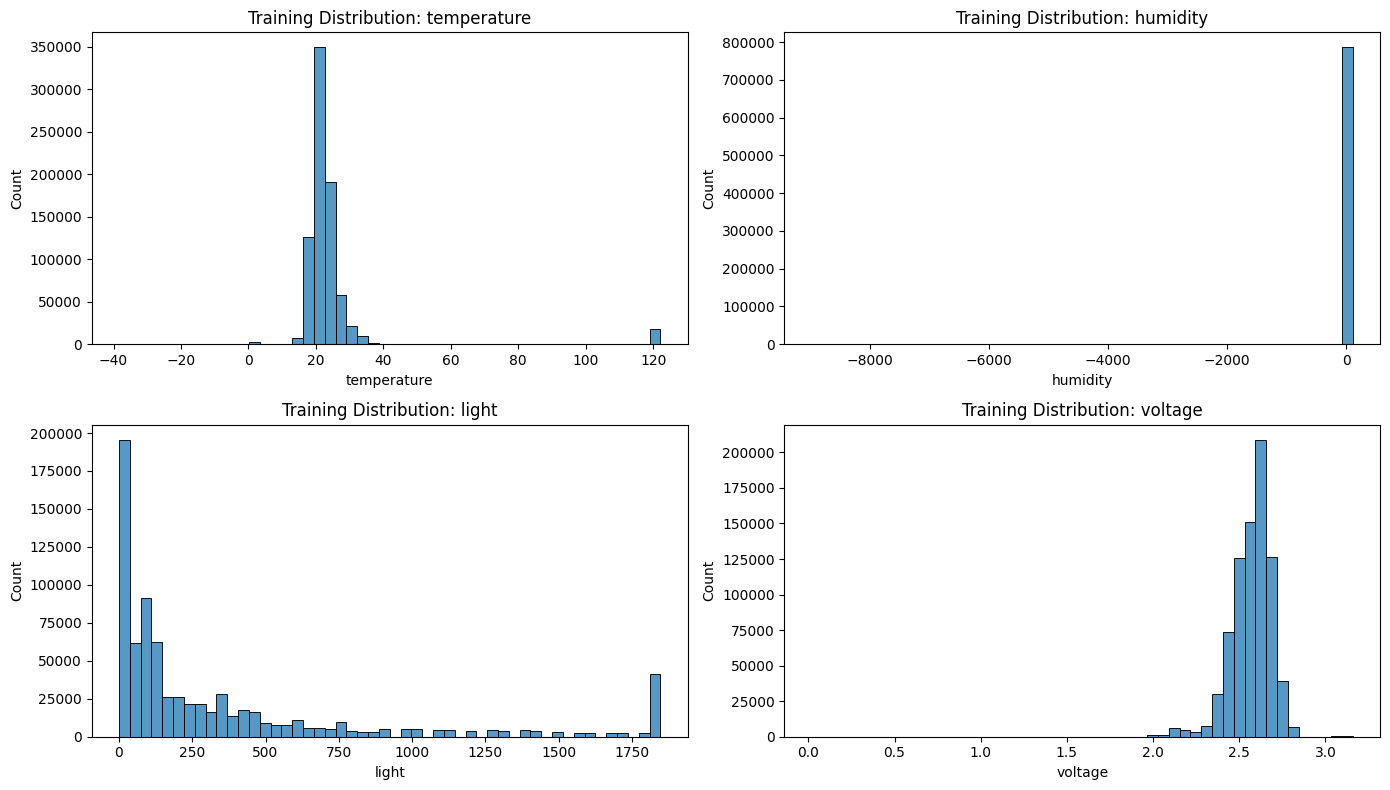

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for col, ax in zip(sensor_cols, axes.flatten()):
    sns.histplot(
        data=df_train,
        x=col,
        bins=50,
        kde=False,
        ax=ax
    )
    ax.set_title(f"Training Distribution: {col}")

plt.tight_layout()
plt.show()

Temperature: most readings are around 15–35°C, but there is a prominent spike near 122.153.


Humidity: the extreme negative value (around -8983) compresses nearly all other readings against zero in the histogram.


Light: the distribution is strongly right-skewed, with many low readings and a long upper tail. Zero may be a valid measurement.


Voltage: most readings cluster around 2.4–2.7 V, with a few lower values that deserve inspection.

In [31]:
# Inspect extreme readings without modifying the dataset
print("Temperature extremes:")
print(
    df_train.loc[
        (df_train["temperature"] < -40) |
        (df_train["temperature"] > 85),
        ["Date", "Time", "moteid", "temperature"]
    ].head(20)
)

print("\nHumidity extremes:")
print(
    df_train.loc[
        (df_train["humidity"] < 0) |
        (df_train["humidity"] > 100),
        ["Date", "Time", "moteid", "humidity"]
    ].head(20)
)

print("\nExact suspicious value counts:")
print("Temperature = 122.153:",
      (df_train["temperature"] == 122.153).sum())

print("Humidity = -8983.13:",
      (df_train["humidity"] == -8983.13).sum())

Temperature extremes:
              Date        Time  moteid  temperature
149688  02-03-2004  7:39:30 AM      15      122.153
149715  02-03-2004  7:40:23 AM      15      122.153
149737  02-03-2004  7:41:00 AM      15      122.153
149746  02-03-2004  7:41:23 AM      15      122.153
149842  02-03-2004  7:44:16 AM      15      122.153
149865  02-03-2004  7:44:58 AM      15      122.153
149872  02-03-2004  7:45:23 AM      15      122.153
149891  02-03-2004  7:45:59 AM      15      122.153
149953  02-03-2004  7:47:54 AM      15      122.153
150059  02-03-2004  7:51:30 AM      15      122.153
150120  02-03-2004  7:53:53 AM      15      122.153
150209  02-03-2004  7:56:29 AM      15      122.153
150273  02-03-2004  7:58:16 AM      15      122.153
150276  02-03-2004  7:58:20 AM      15      122.153
150342  02-03-2004  8:00:08 AM      15      122.153
150393  02-03-2004  8:01:43 AM      15      122.153
150432  02-03-2004  8:03:02 AM      15      122.153
150449  02-03-2004  8:03:30 AM      15    

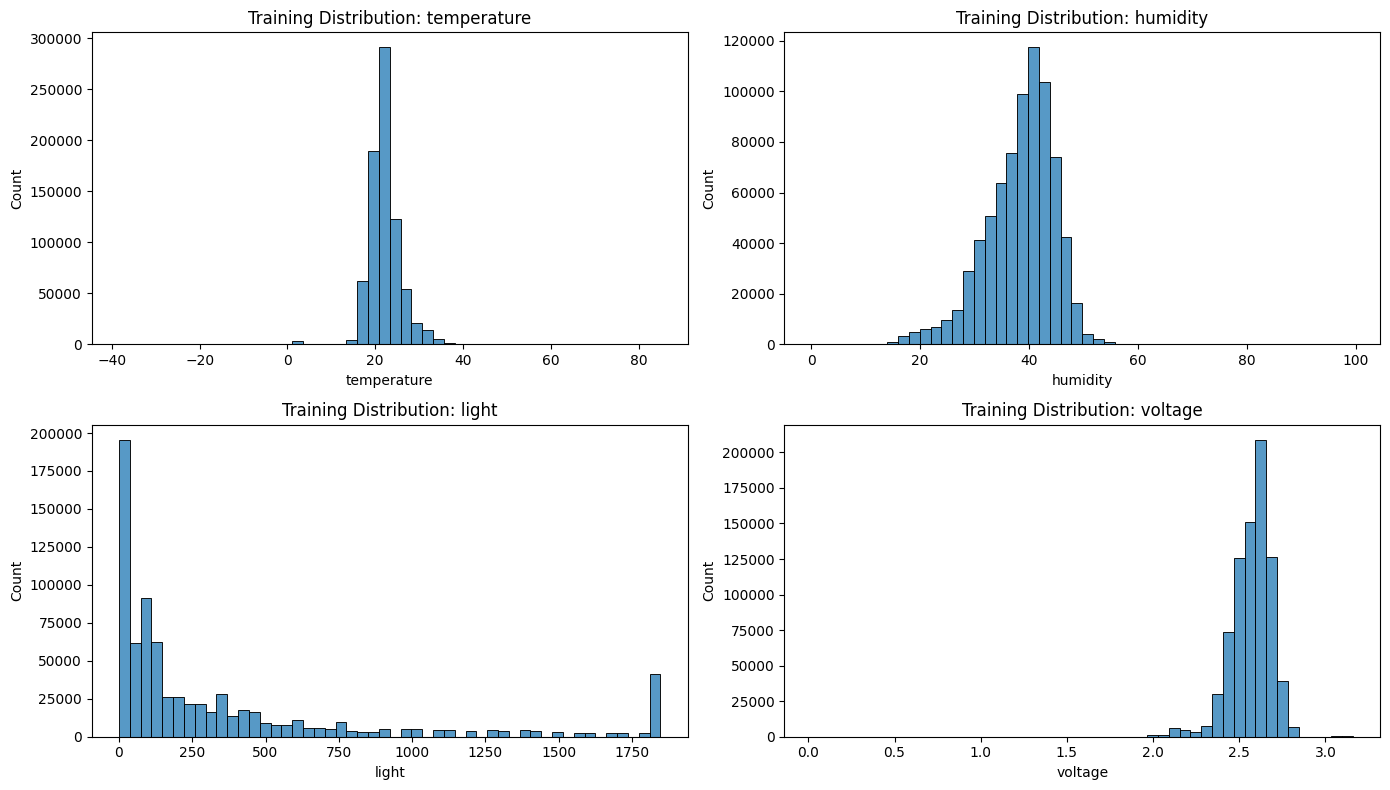

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_data = df_train.copy()

# Temporary visualization filters only
plot_data.loc[
    (plot_data["temperature"] < -40) |
    (plot_data["temperature"] > 85),
    "temperature"
] = float("nan")

plot_data.loc[
    (plot_data["humidity"] < 0) |
    (plot_data["humidity"] > 100),
    "humidity"
] = float("nan")

for col, ax in zip(
    ["temperature", "humidity", "light", "voltage"],
    axes.flatten()
):
    sns.histplot(
        data=plot_data,
        x=col,
        bins=50,
        kde=False,
        ax=ax
    )
    ax.set_title(f"Training Distribution: {col}")

plt.tight_layout()
plt.show()

Temperature 122.153: appears 17,510 times and persists for sensor node 15 across consecutive readings. This could be a sensor fault, a dataset sentinel, or a recording issue; it should not automatically be classified as an attack.

Humidity -4.0: appears repeatedly, and -1854.52 is another extreme value. These require investigation and likely invalid-value handling after checking the dataset's encoding.

After temporary filtering for visualization: temperature and humidity show much more interpretable distributions. Light remains right-skewed, and voltage is concentrated around 2.5–2.7 V.

#### quantify suspicious values per sensor

To see whether the unusual values are concentrated in specific nodes

In [33]:
# Count suspicious measurements by sensor node
print("Temperature sentinel counts by node:")
print(
    df_train.loc[
        df_train["temperature"] == 122.153
    ].groupby("moteid").size().sort_values(ascending=False)
)

print("\nHumidity = -4 counts by node:")
print(
    df_train.loc[
        df_train["humidity"] == -4.0
    ].groupby("moteid").size().sort_values(ascending=False)
)

print("\nHumidity below zero by node:")
print(
    df_train.loc[
        df_train["humidity"] < 0
    ].groupby("moteid").size().sort_values(ascending=False)
)

Temperature sentinel counts by node:
moteid
18    8911
16    4051
17    3522
19     661
15     337
8       14
20      14
dtype: int64

Humidity = -4 counts by node:
moteid
18    1556
17     887
16     742
15     209
20      17
8       12
4        1
dtype: int64

Humidity below zero by node:
moteid
18    9589
16    3909
17    3480
15     216
19      61
20      17
8       13
2        1
4        1
dtype: int64


Node 18 has 8,911 temperature readings equal to 122.153 and 9,589 negative humidity readings. Nodes 16 and 17 also have substantial numbers of these readings.

### quantify the affected readings